In [2]:
%pip install numpy pandas librosa matplotlib

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    ----------------

In [3]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [4]:
PCG_DIR = "../data/PCG"

print("PCG folder exists:", os.path.exists(PCG_DIR))

PCG folder exists: True


In [5]:
wav_files = [f for f in os.listdir(PCG_DIR) if f.lower().endswith(".wav")]

print("Number of WAV files:", len(wav_files))
print("First 10 files:", wav_files[:10])

Number of WAV files: 0
First 10 files: []


In [6]:
items = os.listdir(PCG_DIR)

print("Number of items:", len(items))
print("First 30 items:")
for item in items[:30]:
    print(item)

Number of items: 2
First 30 items:
extracted
raw


In [7]:
raw_dir = os.path.join(PCG_DIR, "raw")
extracted_dir = os.path.join(PCG_DIR, "extracted")

print("RAW folder:")
print(os.listdir(raw_dir)[:20])

print("\nEXTRACTED folder:")
print(os.listdir(extracted_dir)[:20])

RAW folder:
['Rhd detection using phonocardiogram.zip']

EXTRACTED folder:
['Rhd detection using phonocardiogram', 'Rhd detection using phonocardiogram.zip']


In [8]:
dataset_dir = os.path.join(
    PCG_DIR,
    "extracted",
    "Rhd detection using phonocardiogram"
)

print("Dataset folder exists:", os.path.exists(dataset_dir))

wav_files = [
    f for f in os.listdir(dataset_dir)
    if f.lower().endswith(".wav")
]

print("Number of WAV files:", len(wav_files))
print("First 10 files:", wav_files[:10])

Dataset folder exists: True
Number of WAV files: 0
First 10 files: []


In [9]:
print("Contents of dataset folder:")
for item in os.listdir(dataset_dir):
    print(repr(item))

Contents of dataset folder:
'Rhd detection using phonocardiogram'


In [10]:
dataset_dir = os.path.join(
    PCG_DIR,
    "extracted",
    "Rhd detection using phonocardiogram",
    "Rhd detection using phonocardiogram"
)

print("Dataset folder exists:", os.path.exists(dataset_dir))

items = os.listdir(dataset_dir)

print("Number of items:", len(items))
print("First 20 items:")
for item in items[:20]:
    print(item)

Dataset folder exists: True
Number of items: 10
First 20 items:
Dataset
history.pckl
model
model_weights.h5
requirements.txt
rhd_app_fixed.py
rhd_detection_fixed.py
rhd_streamlit_app.py
testRecordings
test_file_handling.py


In [11]:
dataset_folder = os.path.join(dataset_dir, "Dataset")

print("Dataset folder exists:", os.path.exists(dataset_folder))

items = os.listdir(dataset_folder)

print("Number of items:", len(items))
print("First 20 items:")

for item in items[:20]:
    print(item)

Dataset folder exists: True
Number of items: 1230
First 20 items:
a0001.dat
a0001.hea
a0001.wav
a0002.dat
a0002.hea
a0002.wav
a0003.dat
a0003.hea
a0003.wav
a0004.dat
a0004.hea
a0004.wav
a0005.dat
a0005.hea
a0005.wav
a0006.dat
a0006.hea
a0006.wav
a0007.dat
a0007.hea


In [12]:
PCG_DATASET = os.path.join(
    PCG_DIR,
    "extracted",
    "Rhd detection using phonocardiogram",
    "Rhd detection using phonocardiogram",
    "Dataset"
)

wav_files = [
    f for f in os.listdir(PCG_DATASET)
    if f.lower().endswith(".wav")
]

print("Number of WAV files:", len(wav_files))
print("First 10 WAV files:", wav_files[:10])

Number of WAV files: 409
First 10 WAV files: ['a0001.wav', 'a0002.wav', 'a0003.wav', 'a0004.wav', 'a0005.wav', 'a0006.wav', 'a0007.wav', 'a0008.wav', 'a0009.wav', 'a0010.wav']


In [13]:
sample_file = os.path.join(PCG_DATASET, "a0001.wav")

signal, sample_rate = librosa.load(
    sample_file,
    sr=None,
    mono=True
)

print("Sample rate:", sample_rate, "Hz")
print("Number of samples:", len(signal))
print("Duration:", len(signal) / sample_rate, "seconds")
print("Minimum amplitude:", signal.min())
print("Maximum amplitude:", signal.max())

Sample rate: 2000 Hz
Number of samples: 71332
Duration: 35.666 seconds
Minimum amplitude: -0.13742065
Maximum amplitude: 0.20996094


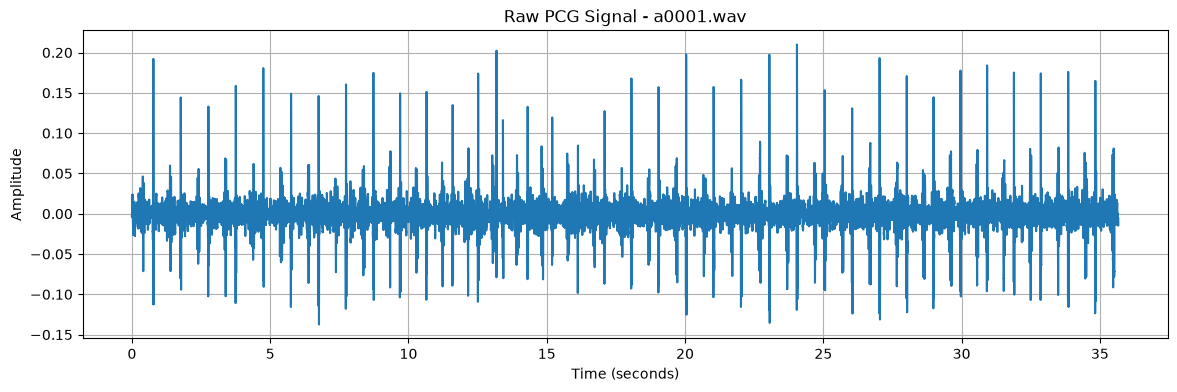

In [14]:
plt.figure(figsize=(14, 4))

time = np.arange(len(signal)) / sample_rate

plt.plot(time, signal)

plt.title("Raw PCG Signal - a0001.wav")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

In [15]:
signal_norm = signal / np.max(np.abs(signal))

print("Original range:")
print(signal.min(), "to", signal.max())

print("\nNormalized range:")
print(signal_norm.min(), "to", signal_norm.max())

Original range:
-0.13742065 to 0.20996094

Normalized range:
-0.6545058 to 1.0


In [16]:
segment_duration = 1.2  # seconds
segment_samples = int(segment_duration * sample_rate)

segments = []

for start in range(0, len(signal_norm) - segment_samples + 1, segment_samples):
    segment = signal_norm[start:start + segment_samples]
    segments.append(segment)

segments = np.array(segments)

print("Segment duration:", segment_duration, "seconds")
print("Samples per segment:", segment_samples)
print("Number of segments:", len(segments))
print("Segment shape:", segments.shape)

Segment duration: 1.2 seconds
Samples per segment: 2400
Number of segments: 29
Segment shape: (29, 2400)


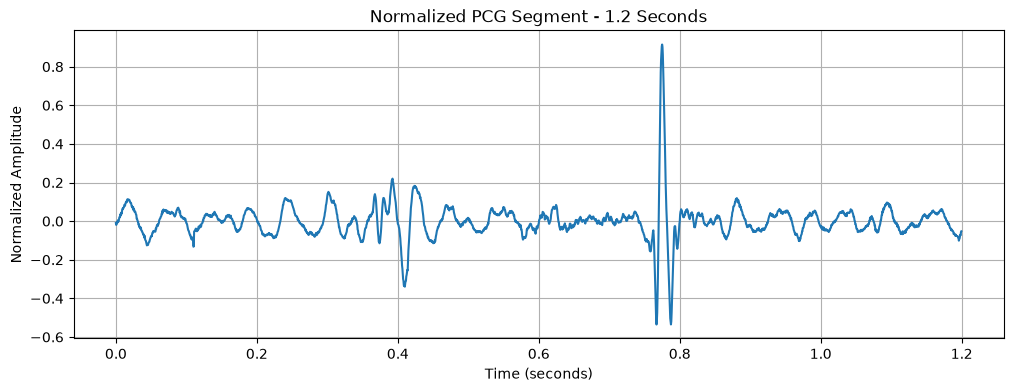

In [17]:
segment = segments[0]

time_segment = np.arange(len(segment)) / sample_rate

plt.figure(figsize=(12, 4))

plt.plot(time_segment, segment)

plt.title("Normalized PCG Segment - 1.2 Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True)

plt.show()

In [18]:
n_mels = 40

mel_spectrogram = librosa.feature.melspectrogram(
    y=segments[0],
    sr=sample_rate,
    n_mels=n_mels,
    n_fft=256,
    hop_length=128
)

log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

print("Log-Mel spectrogram shape:", log_mel.shape)

Log-Mel spectrogram shape: (40, 19)


1.2-sec PCG segment
       
        
        ↓
  
   
   Mel Spectrogram
        
        
        ↓


Convert power → dB
       
        
        ↓
    
    
    Log-Mel image
      
        
        ↓
       
       
       2D CNN

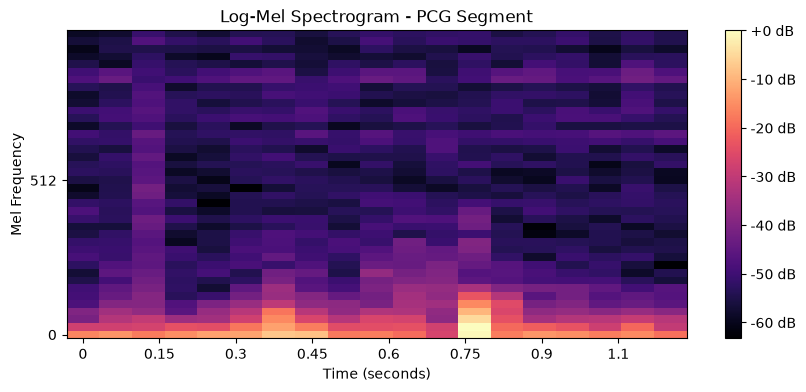

In [19]:
plt.figure(figsize=(10, 4))

librosa.display.specshow(
    log_mel,
    sr=sample_rate,
    hop_length=128,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram - PCG Segment")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")

plt.show()

In [21]:
reference_file = os.path.join(PCG_DATASET, "REFERENCE.csv")

reference_df = pd.read_csv(
    reference_file,
    header=None,
    names=["recording", "label"]
)

print("Number of records:", len(reference_df))
print("\nLabel distribution:")
print(reference_df["label"].value_counts())

print("\nFirst 5 records:")
print(reference_df.head())

Number of records: 409

Label distribution:
label
 1    292
-1    117
Name: count, dtype: int64

First 5 records:
  recording  label
0     a0001      1
1     a0002      1
2     a0003      1
3     a0004      1
4     a0005      1


In [22]:
PROCESSED_PCG_DIR = "../processed/PCG"

os.makedirs(PROCESSED_PCG_DIR, exist_ok=True)

print("Processed PCG folder exists:",
      os.path.exists(PROCESSED_PCG_DIR))

Processed PCG folder exists: True


In [23]:
all_spectrograms = []
all_labels = []
all_recording_ids = []

segment_duration = 1.2
n_mels = 40
n_fft = 256
hop_length = 128

for _, row in reference_df.iterrows():

    recording_id = row["recording"]
    label = row["label"]

    wav_path = os.path.join(
        PCG_DATASET,
        recording_id + ".wav"
    )

    # Load PCG
    signal, sr = librosa.load(
        wav_path,
        sr=None,
        mono=True
    )

    # Normalize
    max_amplitude = np.max(np.abs(signal))

    if max_amplitude == 0:
        continue

    signal_norm = signal / max_amplitude

    # Segment
    segment_samples = int(segment_duration * sr)

    for start in range(
        0,
        len(signal_norm) - segment_samples + 1,
        segment_samples
    ):

        segment = signal_norm[
            start:start + segment_samples
        ]

        # Log-Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_mels=n_mels,
            n_fft=n_fft,
            hop_length=hop_length
        )

        log_mel = librosa.power_to_db(
            mel,
            ref=np.max
        )

        all_spectrograms.append(log_mel)
        all_labels.append(label)
        all_recording_ids.append(recording_id)

print("Total segments:", len(all_spectrograms))
print("Labels stored:", len(all_labels))
print("Recording IDs stored:", len(all_recording_ids))

Total segments: 10866
Labels stored: 10866
Recording IDs stored: 10866


In [24]:
spectrogram_array = np.array(all_spectrograms, dtype=np.float32)

metadata_df = pd.DataFrame({
    "recording_id": all_recording_ids,
    "label": all_labels
})

spectrogram_path = os.path.join(
    PROCESSED_PCG_DIR,
    "pcg_spectrograms.npy"
)

metadata_path = os.path.join(
    PROCESSED_PCG_DIR,
    "pcg_metadata.csv"
)

np.save(spectrogram_path, spectrogram_array)
metadata_df.to_csv(metadata_path, index=False)

print("Spectrogram shape:", spectrogram_array.shape)
print("Metadata shape:", metadata_df.shape)
print("Saved spectrograms:", os.path.exists(spectrogram_path))
print("Saved metadata:", os.path.exists(metadata_path))

Spectrogram shape: (10866, 40, 19)
Metadata shape: (10866, 2)
Saved spectrograms: True
Saved metadata: True


In [25]:
loaded_spectrograms = np.load(spectrogram_path)
loaded_metadata = pd.read_csv(metadata_path)

print("Loaded spectrogram shape:", loaded_spectrograms.shape)
print("Loaded metadata shape:", loaded_metadata.shape)

print("\nUnique recordings:",
      loaded_metadata["recording_id"].nunique())

print("\nLabel distribution:")
print(loaded_metadata["label"].value_counts())

Loaded spectrogram shape: (10866, 40, 19)
Loaded metadata shape: (10866, 2)

Unique recordings: 409

Label distribution:
label
 1    7767
-1    3099
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

# Get one row per recording
recording_labels = (
    loaded_metadata[["recording_id", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total recordings:", len(recording_labels))
print("\nRecording-level label distribution:")
print(recording_labels["label"].value_counts())

# 70% train, 15% validation, 15% test
train_records, temp_records = train_test_split(
    recording_labels,
    test_size=0.30,
    stratify=recording_labels["label"],
    random_state=42
)

val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    stratify=temp_records["label"],
    random_state=42
)

print("\nTrain recordings:", len(train_records))
print("Validation recordings:", len(val_records))
print("Test recordings:", len(test_records))

Total recordings: 409

Recording-level label distribution:
label
 1    292
-1    117
Name: count, dtype: int64

Train recordings: 286
Validation recordings: 61
Test recordings: 62


In [27]:
id_to_split = {}

for rid in train_records["recording_id"]:
    id_to_split[rid] = "train"

for rid in val_records["recording_id"]:
    id_to_split[rid] = "val"

for rid in test_records["recording_id"]:
    id_to_split[rid] = "test"

# Assign each segment to the split of its original recording
split_labels = loaded_metadata["recording_id"].map(id_to_split)

train_mask = split_labels == "train"
val_mask = split_labels == "val"
test_mask = split_labels == "test"

X_train = loaded_spectrograms[train_mask]
X_val = loaded_spectrograms[val_mask]
X_test = loaded_spectrograms[test_mask]

y_train = loaded_metadata.loc[train_mask, "label"].values
y_val = loaded_metadata.loc[val_mask, "label"].values
y_test = loaded_metadata.loc[test_mask, "label"].values

print("Train:")
print("X:", X_train.shape)
print("y:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("y:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("y:", y_test.shape)

Train:
X: (7601, 40, 19)
y: (7601,)

Validation:
X: (1587, 40, 19)
y: (1587,)

Test:
X: (1678, 40, 19)
y: (1678,)


In [28]:
print("TRAIN label distribution:")
print(pd.Series(y_train).value_counts())

print("\nVALIDATION label distribution:")
print(pd.Series(y_val).value_counts())

print("\nTEST label distribution:")
print(pd.Series(y_test).value_counts())

TRAIN label distribution:
 1    5430
-1    2171
Name: count, dtype: int64

VALIDATION label distribution:
 1    1143
-1     444
Name: count, dtype: int64

TEST label distribution:
 1    1194
-1     484
Name: count, dtype: int64


In [29]:
y_train_binary = (y_train == 1).astype(np.int32)
y_val_binary = (y_val == 1).astype(np.int32)
y_test_binary = (y_test == 1).astype(np.int32)

print("Train labels:", np.unique(y_train_binary, return_counts=True))
print("Validation labels:", np.unique(y_val_binary, return_counts=True))
print("Test labels:", np.unique(y_test_binary, return_counts=True))

Train labels: (array([0, 1], dtype=int32), array([2171, 5430]))
Validation labels: (array([0, 1], dtype=int32), array([ 444, 1143]))
Test labels: (array([0, 1], dtype=int32), array([ 484, 1194]))


In [30]:
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("CNN input shapes:")
print("X_train:", X_train_cnn.shape)
print("X_val:", X_val_cnn.shape)
print("X_test:", X_test_cnn.shape)

print("\nData type:", X_train_cnn.dtype)

CNN input shapes:
X_train: (7601, 40, 19, 1)
X_val: (1587, 40, 19, 1)
X_test: (1678, 40, 19, 1)

Data type: float32


In [31]:
print("Training spectrogram range:")
print("Minimum:", X_train_cnn.min())
print("Maximum:", X_train_cnn.max())

print("\nValidation spectrogram range:")
print("Minimum:", X_val_cnn.min())
print("Maximum:", X_val_cnn.max())

print("\nTest spectrogram range:")
print("Minimum:", X_test_cnn.min())
print("Maximum:", X_test_cnn.max())

Training spectrogram range:
Minimum: -80.0
Maximum: 0.0

Validation spectrogram range:
Minimum: -80.0
Maximum: 0.0

Test spectrogram range:
Minimum: -80.0
Maximum: 0.0


In [33]:
%pip install tensorflow

   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/350.9 MB ? eta -:--:--
   ---------------------------------------- 0.8/350.9 MB 2.1 MB/s eta 0:02:47
   ---------------------------------------- 1.0/350.9 MB 2.2 MB/s eta 0:02:40
   ---------------------------------------- 1.0/350.9 MB 2.2 MB/s eta 0:02:40
   ---------------------------------------- 1.3/350.9 MB 1.5 MB/s eta 0:04:00
   ---------------------------------------- 1.3/350.9 MB 1.5 MB/s eta 0:04:00
   ---------------------------------------- 1.3/350.9 MB 1.5 MB/s eta 0:04:00
   ---------------------------------------- 1.3/350.9 MB 1.5 MB/s eta 0:04:00
   ---------------------------------------- 1.6/350.9 MB 847.3 kB/s eta 0:06:53
   ---------------------------------------- 2.1/350.9 MB 954.7 kB/s eta 0:06:06
   ---------------------------------------- 2.6/350.9 MB 1.1 MB/s eta 0:05:12
   

In [34]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [35]:
model = keras.Sequential([
    layers.Input(shape=(40, 19, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 40, 19, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 40, 19, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 20, 9, 32)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 20, 9, 64)           │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 20, 9, 64)           │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 10, 4, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 10, 4, 128)          │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 10, 4, 128)          │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,889 (398.00 KB)

 Trainable params: 101,441 (396.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [36]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [37]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_binary)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_binary
)

class_weights = dict(zip(classes, class_weights_array))

print("Classes:", classes)
print("Class weights:", class_weights)

Classes: [0 1]
Class weights: {np.int32(0): np.float64(1.7505757715338555), np.int32(1): np.float64(0.6999079189686924)}


In [38]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_pcg_cnn.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

print("Callbacks created successfully.")

Callbacks created successfully.


In [39]:
history = model.fit(
    X_train_cnn,
    y_train_binary,
    validation_data=(X_val_cnn, y_val_binary),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/30
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6941 - auc: 0.7713 - loss: 0.5742 - precision: 0.8606 - recall: 0.6823
Epoch 1: val_auc improved from None to 0.73238, saving model to best_pcg_cnn.keras

Epoch 1: finished saving model to best_pcg_cnn.keras
238/238 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6941 - auc: 0.7713 - loss: 0.5742 - precision: 0.8606 - recall: 0.6823 - val_accuracy: 0.7202 - val_auc: 0.7324 - val_loss: 0.5801 - val_precision: 0.7202 - val_recall: 1.0000
Epoch 2/30
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7348 - auc: 0.8271 - loss: 0.5095 - precision: 0.8944 - recall: 0.7129
Epoch 2: val_auc improved from 0.73238 to 0.82274, saving model to best_pcg_cnn.keras

Epoch 2: finished saving model to best_pcg_cnn.keras
238/238 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.7348 - auc: 0.8271 - loss: 0.5095 - precision: 0.8944 - recall: 0.7129 - val_accuracy: 0.4045 - val_auc: 0.8227 - val_loss: 1.0471 - val_precision: 0.9714 - v

In [40]:
print("Best validation AUC:", max(history.history["val_auc"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Epochs trained:", len(history.history["loss"]))

Best validation AUC: 0.8625466227531433
Best validation accuracy: 0.7933207154273987
Epochs trained: 11


In [41]:
test_results = model.evaluate(
    X_test_cnn,
    y_test_binary,
    verbose=1
)

print("Test evaluation:")
for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6943 - auc: 0.7719 - loss: 0.5680 - precision: 0.8443 - recall: 0.6993
Test evaluation:
loss: 0.5680
compile_metrics: 0.6943


In [42]:
test_probabilities = model.predict(
    X_test_cnn,
    verbose=1
).ravel()

print("Number of test segment predictions:", len(test_probabilities))
print("Minimum probability:", test_probabilities.min())
print("Maximum probability:", test_probabilities.max())
print("First 10 probabilities:", test_probabilities[:10])

53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Number of test segment predictions: 1678
Minimum probability: 0.017255425
Maximum probability: 0.99205333
First 10 probabilities: [0.8480644  0.90282243 0.82185185 0.68669903 0.6438023  0.74520624
 0.9578003  0.7893453  0.7281214  0.61986274]


In [43]:
test_prediction_df = loaded_metadata.loc[test_mask].copy()

test_prediction_df["probability"] = test_probabilities

print(test_prediction_df.head())
print("\nRows:", len(test_prediction_df))
print("Unique recordings:", test_prediction_df["recording_id"].nunique())

    recording_id  label  probability
204        a0009     -1     0.848064
205        a0009     -1     0.902822
206        a0009     -1     0.821852
207        a0009     -1     0.686699
208        a0009     -1     0.643802

Rows: 1678
Unique recordings: 62


In [44]:
recording_level_df = (
    test_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

print(recording_level_df.head(10))

print("\nNumber of recordings:", len(recording_level_df))
print("\nTrue label distribution:")
print(recording_level_df["true_label"].value_counts())

print("\nProbability range:")
print(
    recording_level_df["predicted_probability"].min(),
    "to",
    recording_level_df["predicted_probability"].max()
)

  recording_id  true_label  predicted_probability  num_segments
0        a0009          -1               0.817013            29
1        a0011          -1               0.237000            29
2        a0018           1               0.371850            17
3        a0040           1               0.642742            29
4        a0043           1               0.231534            29
5        a0048           1               0.597226            30
6        a0051           1               0.945019            29
7        a0058           1               0.804516            17
8        a0072           1               0.530420            30
9        a0073           1               0.602885            29

Number of recordings: 62

True label distribution:
true_label
 1    44
-1    18
Name: count, dtype: int64

Probability range:
0.06331736 to 0.94501853


In [45]:
recording_level_df = (
    test_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

print(recording_level_df.head(10))

print("\nNumber of recordings:", len(recording_level_df))
print("\nTrue label distribution:")
print(recording_level_df["true_label"].value_counts())

print("\nProbability range:")
print(
    recording_level_df["predicted_probability"].min(),
    "to",
    recording_level_df["predicted_probability"].max()
)

  recording_id  true_label  predicted_probability  num_segments
0        a0009          -1               0.817013            29
1        a0011          -1               0.237000            29
2        a0018           1               0.371850            17
3        a0040           1               0.642742            29
4        a0043           1               0.231534            29
5        a0048           1               0.597226            30
6        a0051           1               0.945019            29
7        a0058           1               0.804516            17
8        a0072           1               0.530420            30
9        a0073           1               0.602885            29

Number of recordings: 62

True label distribution:
true_label
 1    44
-1    18
Name: count, dtype: int64

Probability range:
0.06331736 to 0.94501853


In [46]:
from sklearn.metrics import roc_auc_score

recording_true = (recording_level_df["true_label"] == 1).astype(int)

recording_auc = roc_auc_score(
    recording_true,
    recording_level_df["predicted_probability"]
)

print("Recording-level ROC-AUC:", recording_auc)

Recording-level ROC-AUC: 0.8118686868686869


In [47]:
from sklearn.metrics import roc_curve

# Validation probabilities
val_probabilities = model.predict(
    X_val_cnn,
    verbose=1
).ravel()

# ROC curve on validation data
fpr, tpr, thresholds = roc_curve(
    y_val_binary,
    val_probabilities
)

# Youden's Index
youden_index = tpr - fpr

best_idx = np.argmax(youden_index)
best_threshold = thresholds[best_idx]

print("Best validation threshold:", best_threshold)
print("Validation sensitivity:", tpr[best_idx])
print("Validation specificity:", 1 - fpr[best_idx])
print("Youden's Index:", youden_index[best_idx])

50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Best validation threshold: 0.37780794501304626
Validation sensitivity: 0.7077865266841645
Validation specificity: 0.8761261261261262
Youden's Index: 0.5839126528102907


In [48]:
recording_level_df["predicted_label"] = (
    recording_level_df["predicted_probability"] >= best_threshold
).astype(int)

print(
    recording_level_df[
        [
            "recording_id",
            "true_label",
            "predicted_probability",
            "predicted_label"
        ]
    ].head(10)
)

print("\nPredicted label distribution:")
print(recording_level_df["predicted_label"].value_counts())

  recording_id  true_label  predicted_probability  predicted_label
0        a0009          -1               0.817013                1
1        a0011          -1               0.237000                0
2        a0018           1               0.371850                0
3        a0040           1               0.642742                1
4        a0043           1               0.231534                0
5        a0048           1               0.597226                1
6        a0051           1               0.945019                1
7        a0058           1               0.804516                1
8        a0072           1               0.530420                1
9        a0073           1               0.602885                1

Predicted label distribution:
predicted_label
1    47
0    15
Name: count, dtype: int64


In [49]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Convert true labels: 1 → 1, -1 → 0
true_binary = (
    recording_level_df["true_label"] == 1
).astype(int)

predicted_binary = recording_level_df["predicted_label"]

# Confusion matrix
cm = confusion_matrix(true_binary, predicted_binary)

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(true_binary, predicted_binary)
precision = precision_score(true_binary, predicted_binary)
sensitivity = recall_score(true_binary, predicted_binary)
specificity = tn / (tn + fp)
f1 = f1_score(true_binary, predicted_binary)

print("Confusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nRecording-level metrics:")
print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1-score:    {f1:.4f}")

Confusion Matrix:
[[11  7]
 [ 4 40]]

TN: 11
FP: 7
FN: 4
TP: 40

Recording-level metrics:
Accuracy:    0.8226
Precision:   0.8511
Sensitivity: 0.9091
Specificity: 0.6111
F1-score:    0.8791
